# Benchmark — KD-Tree vs KNN por fuerza bruta

In [1]:

from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.product_features import (
    build_product_features,
    FEATURE_COLUMNS
)

DATA_PATH = PROJECT_DIR / "data" / "raw" / "2019-Oct.csv"

df = pd.read_csv(DATA_PATH, nrows=100_000)

features = build_product_features(
    df.to_dict("records")
)

X = features[FEATURE_COLUMNS].to_numpy(
    dtype=np.float64
)

print("=== DATOS DEL BENCHMARK ===")
print("Eventos:", len(df))
print("Productos:", len(features))
print("Dimensiones:", X.shape[1])

assert X.shape == (20621, 4)


=== DATOS DEL BENCHMARK ===
Eventos: 100000
Productos: 20621
Dimensiones: 4


## 2. Medición de rendimiento

In [2]:

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KDTree, NearestNeighbors

# Normalizar una sola vez para ambas alternativas
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rng = np.random.default_rng(42)

N_QUERIES = 100
REPETITIONS = 10
K = 5
ABS_TOL = 1e-7

query_positions = rng.choice(
    len(X_scaled),
    size=N_QUERIES,
    replace=False
)

query_vectors = X_scaled[query_positions]

# Medir construcción
start = time.perf_counter()
kd_tree = KDTree(
    X_scaled,
    leaf_size=40,
    metric="euclidean"
)
build_kd_ms = (time.perf_counter() - start) * 1000

start = time.perf_counter()
brute_model = NearestNeighbors(
    algorithm="brute",
    metric="euclidean"
)
brute_model.fit(X_scaled)
build_brute_ms = (time.perf_counter() - start) * 1000

# Calentamiento para reducir costos iniciales
for q in query_vectors[:10]:
    kd_tree.query(q.reshape(1, -1), k=K + 1)
    brute_model.kneighbors(
        q.reshape(1, -1),
        n_neighbors=K + 1
    )

measurements = []

# Alternar qué método se ejecuta primero
# para reducir sesgos sistemáticos de orden.
for repetition in range(REPETITIONS):
    for query_id, vector in enumerate(query_vectors):
        q = vector.reshape(1, -1)

        if (repetition + query_id) % 2 == 0:
            methods = ["kd_tree", "brute"]
        else:
            methods = ["brute", "kd_tree"]

        for method in methods:
            start = time.perf_counter_ns()

            if method == "kd_tree":
                distances, indices = kd_tree.query(
                    q, k=K + 1
                )
            else:
                distances, indices = brute_model.kneighbors(
                    q, n_neighbors=K + 1
                )

            elapsed_ms = (
                time.perf_counter_ns() - start
            ) / 1e6

            measurements.append({
                "repetition": repetition,
                "query_id": query_id,
                "method": method,
                "latency_ms": elapsed_ms
            })

df_times = pd.DataFrame(measurements)

summary = df_times.groupby("method")[
    "latency_ms"
].agg(
    median_ms="median",
    mean_ms="mean",
    p95_ms=lambda s: np.percentile(s, 95)
).reset_index()

print("=== CONSTRUCCIÓN ===")
print(f"KD-Tree: {build_kd_ms:.4f} ms")
print(f"Fuerza bruta: {build_brute_ms:.4f} ms")

print("\n=== LATENCIAS ===")
display(summary.round(4))

# Estimar memoria del índice
# KDTree.get_arrays() devuelve sus arreglos internos.
kd_memory = sum(
    arr.nbytes for arr in kd_tree.get_arrays()
)

# Fuerza bruta conserva la matriz de entrenamiento
brute_memory = brute_model._fit_X.nbytes

print("\n=== MEMORIA ESTIMADA ===")
print(f"KD-Tree: {kd_memory / 1024**2:.4f} MiB")
print(f"Fuerza bruta: {brute_memory / 1024**2:.4f} MiB")


=== CONSTRUCCIÓN ===
KD-Tree: 9.2231 ms
Fuerza bruta: 0.5385 ms

=== LATENCIAS ===


,method,median_ms,mean_ms,p95_ms
0,brute,0.3034,0.3174,0.3944
1,kd_tree,0.0699,0.0727,0.1019



=== MEMORIA ESTIMADA ===
KD-Tree: 0.8803 MiB
Fuerza bruta: 0.6293 MiB


In [3]:

# Comparar ambos métodos en las 100 consultas
dist_kd, idx_kd = kd_tree.query(
    query_vectors,
    k=K + 1
)

dist_brute, idx_brute = brute_model.kneighbors(
    query_vectors,
    n_neighbors=K + 1
)

# Los resultados incluyen el propio producto.
# Aquí comprobamos distancias ordenadas, considerando
# tolerancia numérica y posibles empates.
correct_queries = np.all(
    np.isclose(
        dist_kd,
        dist_brute,
        atol=ABS_TOL,
        rtol=0
    ),
    axis=1
)

print("=== VALIDACIÓN DE EXACTITUD ===")
print("Consultas:", len(correct_queries))
print("Distancias equivalentes:", correct_queries.sum())
print(
    "Porcentaje:",
    f"{correct_queries.mean():.2%}"
)
print(
    "Diferencia máxima:",
    np.max(np.abs(dist_kd - dist_brute))
)

assert correct_queries.all()

print("\n¡Benchmark validado correctamente!")


=== VALIDACIÓN DE EXACTITUD ===
Consultas: 100
Distancias equivalentes: 100
Porcentaje: 100.00%
Diferencia máxima: 4.2146848510894035e-08

¡Benchmark validado correctamente!


## 3. Exportación de resultados del benchmark

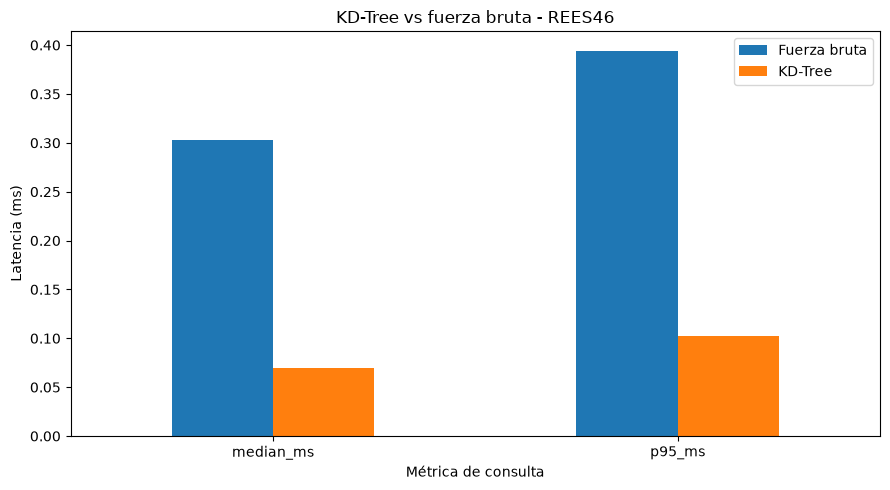

Resultados y gráfico guardados correctamente.


In [4]:

import matplotlib.pyplot as plt

results_dir = PROJECT_DIR / "results"
figures_dir = PROJECT_DIR / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Guardar latencias individuales y resumen
df_times.to_csv(
    results_dir / "benchmark_kdtree_latencies.csv",
    index=False
)

summary.to_csv(
    results_dir / "benchmark_kdtree_summary.csv",
    index=False
)

# Preparar gráfico comparativo
plot_data = summary.set_index("method")[
    ["median_ms", "p95_ms"]
].T

ax = plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("KD-Tree vs fuerza bruta - REES46")
ax.set_ylabel("Latencia (ms)")
ax.set_xlabel("Métrica de consulta")
ax.legend(["Fuerza bruta", "KD-Tree"])

plt.tight_layout()

plt.savefig(
    figures_dir / "benchmark_kdtree_vs_brute.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Resultados y gráfico guardados correctamente.")


## 4. Benchmark de escalabilidad según número de productos

In [5]:

import numpy as np
import pandas as pd
import time

from sklearn.neighbors import KDTree, NearestNeighbors

SIZES = [1000, 5000, 10000, len(X_scaled)]
N_QUERIES = 100
REPETITIONS = 5
K = 5

rng = np.random.default_rng(42)

# Permutación fija: muestras anidadas y reproducibles
permutation = rng.permutation(len(X_scaled))

results_scalability = []

for n in SIZES:

    X_subset = np.ascontiguousarray(
        X_scaled[permutation[:n]]
    )

    query_indices = rng.choice(
        n,
        size=N_QUERIES,
        replace=False
    )

    queries = X_subset[query_indices]

    for method in ["kd_tree", "brute"]:

        build_times = []
        query_times = []

        for repetition in range(REPETITIONS):

            start = time.perf_counter()

            if method == "kd_tree":
                model = KDTree(
                    X_subset,
                    leaf_size=40,
                    metric="euclidean"
                )
            else:
                model = NearestNeighbors(
                    algorithm="brute",
                    metric="euclidean"
                )
                model.fit(X_subset)

            build_times.append(
                (time.perf_counter() - start) * 1000
            )

            # Calentamiento
            for q in queries[:5]:
                if method == "kd_tree":
                    model.query(q.reshape(1, -1), k=K+1)
                else:
                    model.kneighbors(
                        q.reshape(1, -1),
                        n_neighbors=K+1
                    )

            # Consultas individuales
            for q in queries:

                start = time.perf_counter_ns()

                if method == "kd_tree":
                    model.query(
                        q.reshape(1, -1), k=K+1
                    )
                else:
                    model.kneighbors(
                        q.reshape(1, -1),
                        n_neighbors=K+1
                    )

                query_times.append(
                    (time.perf_counter_ns() - start) / 1e6
                )

        # Memoria estimada de arreglos
        if method == "kd_tree":
            memory_bytes = sum(
                arr.nbytes for arr in model.get_arrays()
            )
        else:
            memory_bytes = model._fit_X.nbytes

        results_scalability.append({
            "productos": n,
            "metodo": method,
            "construccion_ms": np.median(build_times),
            "latencia_mediana_ms": np.median(query_times),
            "latencia_p95_ms": np.percentile(query_times, 95),
            "memoria_MiB": memory_bytes / 1024**2
        })

df_scalability = pd.DataFrame(results_scalability)

print("=== BENCHMARK DE ESCALABILIDAD ===")
display(df_scalability.round(4))

print("\n¡Benchmark de escalabilidad completado!")


=== BENCHMARK DE ESCALABILIDAD ===


,productos,metodo,construccion_ms,latencia_mediana_ms,latencia_p95_ms,memoria_MiB
0,1000,kd_tree,0.2593,0.0407,0.0545,0.0410
1,1000,brute,0.1592,0.1105,0.1571,0.0305
2,5000,kd_tree,1.5454,0.0468,0.0600,0.2024
3,5000,brute,0.1812,0.1536,0.2594,0.1526
4,10000,kd_tree,3.4801,0.0507,0.0614,0.4048
5,10000,brute,0.1927,0.2027,0.3170,0.3052
6,20621,kd_tree,8.9649,0.0532,0.0800,0.8803
7,20621,brute,0.1912,0.3027,0.3991,0.6293



¡Benchmark de escalabilidad completado!


In [6]:

comparison = df_scalability.pivot(
    index="productos",
    columns="metodo",
    values="latencia_mediana_ms"
)

comparison["speedup"] = (
    comparison["brute"] / comparison["kd_tree"]
)

print("=== ACELERACIÓN POR TAMAÑO ===")
display(comparison.round(4))

# Validar resultados
assert df_scalability.shape[0] == 8
assert (df_scalability["latencia_mediana_ms"] > 0).all()
assert (df_scalability["memoria_MiB"] > 0).all()

print("\nComparación generada correctamente.")


=== ACELERACIÓN POR TAMAÑO ===


metodo,brute,kd_tree,speedup
productos,,,
1000,0.1105,0.0407,2.7150
5000,0.1536,0.0468,3.2810
10000,0.2027,0.0507,3.9980
20621,0.3027,0.0532,5.6898



Comparación generada correctamente.


## 5. Exportación del benchmark de escalabilidad

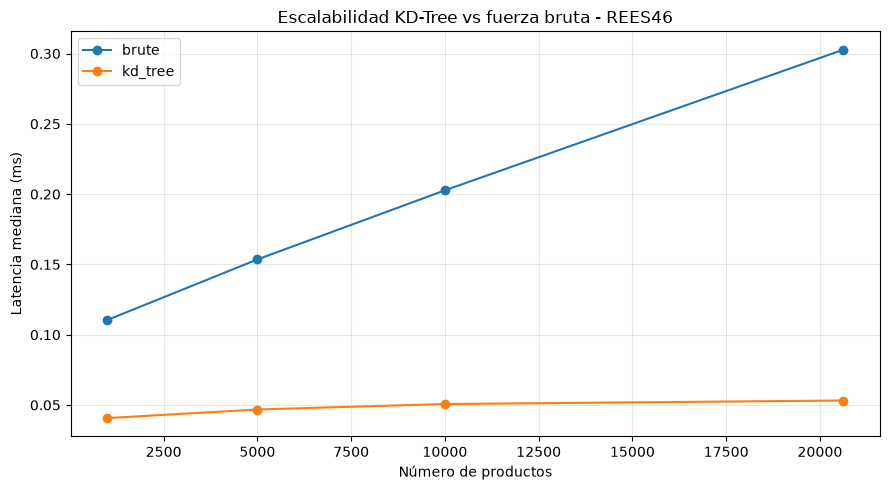

Benchmark de escalabilidad guardado correctamente.


In [7]:

import matplotlib.pyplot as plt

results_dir = PROJECT_DIR / "results"
figures_dir = PROJECT_DIR / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Guardar resultados
df_scalability.to_csv(
    results_dir / "benchmark_kdtree_scalability.csv",
    index=False
)

comparison.to_csv(
    results_dir / "benchmark_kdtree_speedup.csv"
)

# Gráfico de latencias
fig, ax = plt.subplots(figsize=(9, 5))

for method, group in df_scalability.groupby("metodo"):
    group = group.sort_values("productos")

    ax.plot(
        group["productos"],
        group["latencia_mediana_ms"],
        marker="o",
        label=method
    )

ax.set_title("Escalabilidad KD-Tree vs fuerza bruta - REES46")
ax.set_xlabel("Número de productos")
ax.set_ylabel("Latencia mediana (ms)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / "benchmark_kdtree_scalability.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Benchmark de escalabilidad guardado correctamente.")


## 6. Verificación del escenario de 1,000 productos

In [8]:

import time
import numpy as np
from sklearn.neighbors import KDTree, NearestNeighbors

X_1k = np.ascontiguousarray(
    X_scaled[permutation[:1000]]
)

rng_check = np.random.default_rng(123)
query_ids = rng_check.choice(1000, size=100, replace=False)
queries_1k = X_1k[query_ids]

kd_1k = KDTree(X_1k, leaf_size=40)
brute_1k = NearestNeighbors(
    algorithm="brute",
    metric="euclidean",
    n_jobs=1
).fit(X_1k)

# Calentamiento
for _ in range(3):
    for query in queries_1k:
        q = query.reshape(1, -1)
        kd_1k.query(q, k=6)
        brute_1k.kneighbors(q, n_neighbors=6)

measurements_check = {"kd_tree": [], "brute": []}

for repetition in range(10):
    for j, query in enumerate(queries_1k):
        q = query.reshape(1, -1)

        methods = (
            ["kd_tree", "brute"]
            if (repetition + j) % 2 == 0
            else ["brute", "kd_tree"]
        )

        for method in methods:
            start = time.perf_counter_ns()

            if method == "kd_tree":
                kd_1k.query(q, k=6)
            else:
                brute_1k.kneighbors(q, n_neighbors=6)

            elapsed = (time.perf_counter_ns() - start) / 1e6
            measurements_check[method].append(elapsed)

print("=== VERIFICACIÓN 1,000 PRODUCTOS ===")

for method, times in measurements_check.items():
    print(
        f"{method}: "
        f"mediana={np.median(times):.4f} ms | "
        f"p95={np.percentile(times, 95):.4f} ms"
    )


=== VERIFICACIÓN 1,000 PRODUCTOS ===
kd_tree: mediana=0.0519 ms | p95=0.0796 ms
brute: mediana=0.1108 ms | p95=0.1911 ms
